# Caravan: preliminary EDA

Caravan (Kratzert et al., 2023) is a global, harmonized set of catchment attributes, ERA5-Land meteorological forcing, and daily streamflow for gauged basins. This notebook explores the **US and Australian** Caravan sub-datasets from the project subset, extracted from the Caravan v1.6 CSV release by `src/build_subset.py` and committed under `data/processed/`. The committed data hold **every** extracted gauge; the streamflow quality filter is applied in `notebooks/01_preprocessing.ipynb`, which writes `quality_report.csv` and `basin_list.csv`. **Run notebook 01 first.** Great Britain (CAMELS-GB) is excluded from this analysis.

| key | region |
| --- | --- |
| `camels` | United States (CAMELS) |
| `camelsaus` | Australia (CAMELS-AUS) |

**Setup notes**
- You do **not** need the 29 GB Zenodo archive. The subset is in the repo: `attributes.parquet`, `basin_list.csv`, `quality_report.csv` and the time series in `timeseries/<subset>/part-N.parquet`.
- The time series are **sharded** (five parquet files per region) only so that every committed file stays under GitHub's 100 MB limit. Recombine them with `python src/combine_shards.py` (writes one `data/combined/<subset>.parquet` per region, git-ignored) or `from combine_shards import load_timeseries`. The cell below does this automatically if the combined files are missing or older than the shards.
- To change the quality filter, edit its parameters in notebook 02 and rerun it. To re-extract from the archive (other columns, dates or sub-datasets), see `src/build_subset.py`. The Caravan GitHub repo (`external/Caravan`, a git submodule) only holds processing code, and `pip install caravan` is an unrelated project.

In [1]:
# Load standard-library tools for repository paths and Python import configuration.
import sys
from pathlib import Path

# Import libraries for numeric work, tabular data, plotting, and statistical visualizations.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set consistent plot styling and display a useful number of dataframe columns.
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# Resolve the project root whether the notebook starts from its folder or the repository root.
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
# Add the project source folder so its helper modules can be imported.
sys.path.insert(0, str(REPO / "src"))
# Import the helper that locates and combines the project's sharded time series.
import combine_shards  # recombines the sharded time series

# Reuse the processed-data and combined-time-series paths configured by the helper.
PROCESSED = combine_shards.PROCESSED
COMBINED = combine_shards.COMBINED
# Stop with setup guidance if the prepared project subset is not available.
assert (PROCESSED / "attributes.parquet").exists(), f"processed subset not found in {PROCESSED}; see setup notes above"

# US and Australia only; Great Britain (camelsgb) is excluded
# Map included subset identifiers to region labels used in tables and plots.
REGION = {"camels": "US", "camelsaus": "AUS"}
# Keep only supported subsets that are present in the local data directory.
SUBSETS = [s for s in combine_shards.available_subsets() if s in REGION]
# Report which subsets subsequent cells will analyze.
print("sub-datasets:", SUBSETS)

# The committed time series hold every extracted gauge; notebook 02 decides which ones pass the quality filter.
assert (PROCESSED / "basin_list.csv").exists(), "basin_list.csv not found; run notebooks/02_preprocessing.ipynb first"
KEPT = set(pd.read_csv(PROCESSED / "basin_list.csv")["gauge_id"])
print("kept basins (all regions):", len(KEPT))

sub-datasets: ['camels', 'camelsaus']
kept basins (all regions): 1828


### Compile the sharded time series
Reading a region is much simpler from one file than from five shards. The cell below runs `src/combine_shards.py` (via its `main`) for any region whose `data/combined/<subset>.parquet` is missing or older than its shards (for example after pulling new data). It takes a minute or so.

In [2]:
# Rebuild combined files that are missing or older than the committed shards; reuse the rest.
rebuilt = combine_shards.ensure_combined(SUBSETS)
if not rebuilt:
    print("combined files are up to date in", COMBINED)

combined files are up to date in G:\My Drive\Education\DATA780\data780-group-project\data\combined


## 1. Region comparison
How many basins does each region have, how many have usable streamflow, and how complete is the data?

`quality_report.csv` (written by notebook 02) covers **every** extracted basin, with missingness measured over the quality window (1986-10-01 to 2014-09-30, the span that supplies training and test targets), so it is the right source for basin counts. The committed time series (`data/processed/timeseries`) also hold every extracted basin; time-based plots further down filter to the kept basins with `basin_list.csv`.

In [3]:
# Thresholds used by notebook 02's quality filter (read from its saved config)
import json
cfg = json.loads((PROCESSED / "splits" / "config.json").read_text())
MIN_VALID_YEARS, MAX_MISSING_FRAC = cfg["min_valid_years"], cfg["max_missing_frac"]

# Load the all-basin quality report, indexing by gauge and parsing its date fields.
qr = pd.read_csv(PROCESSED / "quality_report.csv", index_col="gauge_id", parse_dates=["first_valid", "last_valid"])
# Restrict the report to the regions selected for this notebook.
qr = qr[qr["subset"].isin(SUBSETS)].copy()
# Add readable region labels for grouping and charting.
qr["region"] = qr["subset"].map(REGION)
# Mark basins with at least one valid streamflow observation.
qr["has_flow"] = qr["n_valid"] > 0
# Mark basins with no missing streamflow observations.
qr["complete"] = qr["missing_frac"] == 0

# Summarize counts, kept records, and completeness statistics by subset.
summary = qr.groupby("subset").agg(
    basins=("n_valid", "size"),
    with_flow=("has_flow", "sum"),
    usable=("keep", "sum"),
    fully_complete=("complete", "sum"),
    median_valid_years=("valid_years", "median"),
    median_pct_missing=("missing_frac", lambda x: 100 * x.median()),
    max_pct_missing=("missing_frac", lambda x: 100 * x.max()),
)
# Derive counts of basins with no flow and basins that fail the keep filters.
summary.insert(2, "without_flow", summary["basins"] - summary["with_flow"])
# Derive counts of basins with no flow and basins that fail the keep filters.
summary.insert(4, "insufficient", summary["basins"] - summary["usable"])
# Express each subset's kept-basin count as a percentage of all basins.
summary["pct_usable"] = 100 * summary["usable"] / summary["basins"]
# Combine additive counts; recompute medians and percentages over all basins below.
total = summary.sum(numeric_only=True)
# Calculate overall statistics from basin rows, not averages of subset medians.
total["median_valid_years"] = qr.valid_years.median()
total["median_pct_missing"] = 100 * qr.missing_frac.median()
total["max_pct_missing"] = 100 * qr.missing_frac.max()
total["pct_usable"] = 100 * qr.keep.mean()
# Append the overall totals and quality statistics as a final table row.
summary.loc["total"] = total
# Display the table with numeric values rounded to two decimal places.
summary.round(2)

,basins,with_flow,without_flow,usable,insufficient,fully_complete,median_valid_years,median_pct_missing,max_pct_missing,pct_usable
subset,,,,,,,,,,
camels,671.0,671.0,0.0,667.0,4.0,568.0,28.00,0.00,17.85,99.40
camelsaus,561.0,561.0,0.0,541.0,20.0,211.0,27.96,0.13,54.96,96.43
total,1232.0,1232.0,0.0,1208.0,24.0,779.0,28.00,0.00,54.96,98.05


Column guide: **with_flow / without_flow** = basins with / without any valid streamflow day in the window; **usable** = kept by the filters (at least `MIN_VALID_YEARS` of valid flow, at most `MAX_MISSING_FRAC` of window days missing, no negative flows); **insufficient** = pulled but dropped; **fully_complete** = no missing flow days at all.

In [4]:
# Why were basins dropped?
# Select basins excluded by the preprocessing keep criteria.
dropped = qr[~qr["keep"]]
# Count common exclusion reasons separately for each subset.
reasons = pd.DataFrame({
    f"valid record < {MIN_VALID_YEARS} y": (dropped.valid_years < MIN_VALID_YEARS).groupby(dropped.subset).sum(),
    f"> {MAX_MISSING_FRAC:.0%} of days missing": (dropped.missing_frac > MAX_MISSING_FRAC).groupby(dropped.subset).sum(),
    "negative flows": (dropped.n_negative > 0).groupby(dropped.subset).sum(),
    "dropped (any reason)": dropped.groupby("subset").size(),
# Restore subset order and show absent counts as integer zeros.
}).reindex(SUBSETS).fillna(0).astype(int)
reasons

,valid record < 15 y,> 15% of days missing,negative flows,dropped (any reason)
subset,,,,
camels,0,4,0,4
camelsaus,1,20,0,20


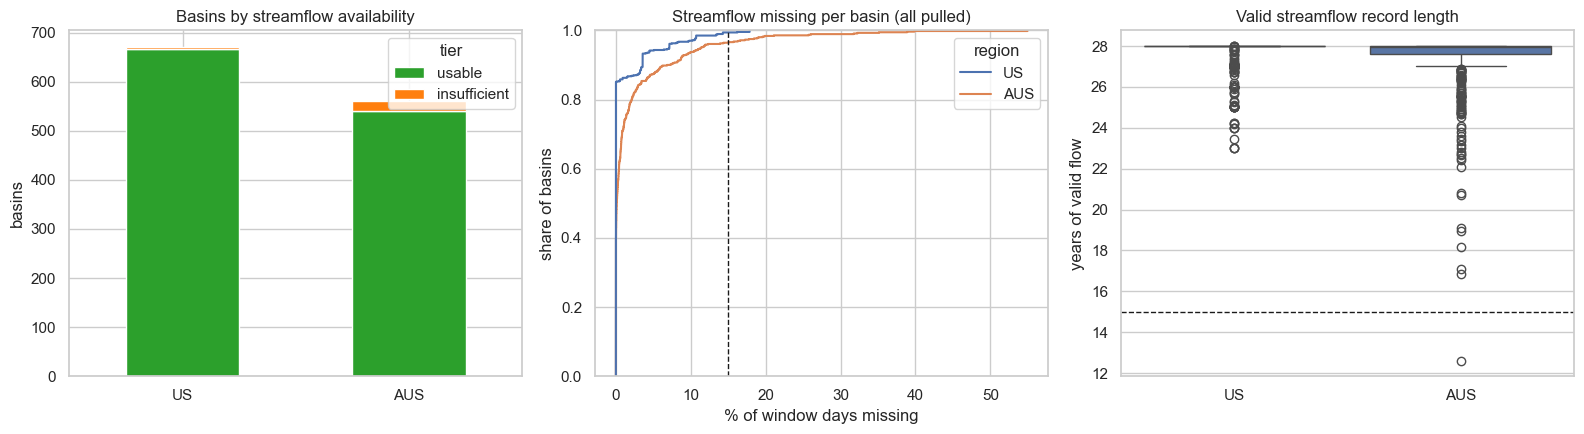

In [5]:
# Preserve a consistent region order across all three panels.
order = [REGION[s] for s in SUBSETS]
# Create panels for basin counts, missingness, and valid-record length.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# stacked basin counts: usable vs insufficient vs no streamflow
# Categorize basins and count the categories by region for the stacked bar chart.
counts = qr.assign(tier=np.select([~qr.has_flow, ~qr.keep], ["no streamflow", "insufficient"], "usable")) \
           .groupby(["region", "tier"]).size().unstack(fill_value=0).reindex(order)
# Arrange categories in the intended legend and stack order.
counts = counts.reindex(columns=[c for c in ["usable", "insufficient", "no streamflow"] if c in counts.columns])
# Show basin counts in each streamflow-availability category.
counts.plot.bar(stacked=True, ax=axes[0], color=["tab:green", "tab:orange", "tab:red"][:counts.shape[1]], rot=0)
# Label the basin-count panel.
axes[0].set(title="Basins by streamflow availability", xlabel="", ylabel="basins")

# distribution of missing streamflow per basin (all pulled basins)
# Compare missing-streamflow distributions across all pulled basins.
sns.ecdfplot(data=qr, x=100 * qr.missing_frac, hue="region", hue_order=order, ax=axes[1])
# Mark the maximum missing-data fraction allowed by the keep criteria.
axes[1].axvline(100 * MAX_MISSING_FRAC, color="k", ls="--", lw=1)
# Label the missingness panel and its percentage scale.
axes[1].set(title="Streamflow missing per basin (all pulled)", xlabel="% of window days missing", ylabel="share of basins")

# valid record length
# Compare valid streamflow-record lengths by region.
sns.boxplot(data=qr, x="region", y="valid_years", order=order, ax=axes[2])
# Mark the minimum number of valid years required to keep a basin.
axes[2].axhline(MIN_VALID_YEARS, color="k", ls="--", lw=1)
# Label the valid-record panel.
axes[2].set(title="Valid streamflow record length", xlabel="", ylabel="years of valid flow")
# Adjust panel spacing and render the comparison figure.
plt.tight_layout(); plt.show()

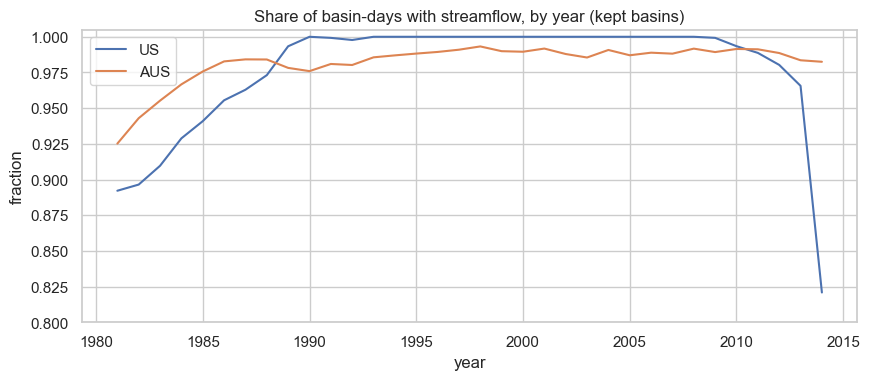

In [6]:
# Completeness over time (kept basins only): share of basin-days with a streamflow value, per year,
# plus per-basin flow statistics reused in section 3
coverage, flow_stats = {}, {}
# Calculate yearly flow coverage and per-basin flow statistics for each subset.
for s in SUBSETS:
    # Read only fields needed for coverage and streamflow summaries.
    q = pd.read_parquet(COMBINED / f"{s}.parquet", columns=["gauge_id", "date", "streamflow"])
    # Keep only basins that pass the quality filter.
    q = q[q["gauge_id"].isin(KEPT)]
    # Measure each year's share of basin-day records with observed streamflow.
    coverage[REGION[s]] = q["streamflow"].notna().groupby(q["date"].dt.year).mean()
    # Store each basin's mean flow, peak flow, and fraction of days with zero flow.
    flow_stats[s] = q.groupby("gauge_id")["streamflow"].agg(q_mean="mean", q_max="max", q_zero=lambda x: (x == 0).mean())
    # Release the region's full time-series table before loading the next one.
    del q

# Plot yearly streamflow coverage for kept basins in each region.
pd.DataFrame(coverage).plot(figsize=(10, 3.8), ylim=(0.8, 1.005))
# Describe the yearly coverage chart and its axes.
plt.title("Share of basin-days with streamflow, by year (kept basins)"); plt.ylabel("fraction"); plt.xlabel("year")
# Render the coverage chart.
plt.show()

In [7]:
# Forcing-variable completeness: % missing per column and region (kept basins)
# Collect forcing-variable missingness separately for each subset.
fmiss = {}
# Examine each included region using its combined time-series file.
for s in SUBSETS:
    # Load the region and remove identifiers so only data columns are measured.
    d = pd.read_parquet(COMBINED / f"{s}.parquet")
    # Keep only basins that pass the quality filter, then drop the identifiers.
    d = d[d["gauge_id"].isin(KEPT)].drop(columns=["gauge_id", "date"])
    # Compute the percentage of missing values in each forcing-variable column.
    fmiss[REGION[s]] = 100 * d.isna().mean()
    # Release this full-region dataframe before moving to the next subset.
    del d
# Arrange per-region missingness series into a comparison table.
fmiss = pd.DataFrame(fmiss)
# Report how many variables have missing values in at least one region.
print("columns with any missing values:", int((fmiss.max(axis=1) > 0).sum()), "of", len(fmiss))
# Display percentages with stronger color for variables with more missing data.
fmiss.round(3).style.background_gradient(cmap="Reds", vmin=0, vmax=max(fmiss.values.max(), 1))

columns with any missing values: 1 of 17


,US,AUS
streamflow,2.358000,1.811000
total_precipitation_sum,0.000000,0.000000
temperature_2m_min,0.000000,0.000000
temperature_2m_mean,0.000000,0.000000
temperature_2m_max,0.000000,0.000000
potential_evaporation_sum_ERA5_LAND,0.000000,0.000000
snow_depth_water_equivalent_mean,0.000000,0.000000
dewpoint_temperature_2m_mean,0.000000,0.000000
surface_net_solar_radiation_mean,0.000000,0.000000
surface_net_thermal_radiation_mean,0.000000,0.000000


**Reading the results** (as of the committed subset; re-check after any rebuild or filter change)
- Every extracted basin has some streamflow in the quality window, so "without streamflow" is empty in both regions; the real split is usable vs. insufficient (98% usable overall: US 99.4%, AUS 96.4%).
- The US loses 4 of 671 basins and AUS 20 of 561, all because more than 15% of window days are missing (AUS has the longest tail, up to 55% missing; one AUS basin also has under 15 valid years); no basin is dropped for negative flows.
- Streamflow is the only incomplete column: all 16 forcing variables are 100% complete, and streamflow is about 1% missing over the kept basins.
- US streamflow coverage drops sharply in 2014 (about 82% of basin-days), because many records end on 2014-09-30. That is the last day of the quality window and of the test period, so the drop no longer affects which basins are kept.
- Time-based plots and the forcing table cover the kept basins only (filtered with `basin_list.csv`). The dropped basins' series are in the committed data too, so they can be inspected directly.

## 2. Static attributes
The committed `attributes.parquet` covers every extracted basin (index `gauge_id`; column `subset`); the cell below keeps the basins that pass the quality filter.

In [8]:
# Load the prepared static catchment attributes for every retained basin.
attrs = pd.read_parquet(PROCESSED / "attributes.parquet")
# Keep only attributes for the regions included in this analysis and the basins that pass the quality filter.
attrs = attrs[attrs["subset"].isin(SUBSETS) & attrs.index.isin(KEPT)]
# Show the number of basin rows and attribute columns.
print(attrs.shape)
# Preview the first few basin records.
attrs.head()

(1208, 216)


,aridity_ERA5_LAND,aridity_FAO_PM,frac_snow,high_prec_dur,high_prec_freq,low_prec_dur,low_prec_freq,moisture_index_ERA5_LAND,moisture_index_FAO_PM,p_mean,pet_mean_ERA5_LAND,pet_mean_FAO_PM,seasonality_ERA5_LAND,seasonality_FAO_PM,sgr_dk_sav,glc_pc_s06,glc_pc_s07,nli_ix_sav,glc_pc_s04,glc_pc_s05,glc_pc_s02,glc_pc_s03,glc_pc_s01,pet_mm_syr,glc_pc_s08,...,cmi_ix_s09,snw_pc_s10,snw_pc_s11,snw_pc_s12,cmi_ix_s03,cmi_ix_s04,cmi_ix_s01,cmi_ix_s02,pst_pc_sse,dis_m3_pmn,dis_m3_pmx,dis_m3_pyr,lkv_mc_usu,rev_mc_usu,ria_ha_usu,riv_tc_usu,pop_ct_usu,dor_pc_pva,area_fraction_used_for_aggregation,gauge_name,country,gauge_lat,gauge_lon,area,subset
gauge_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
camels_01013500,3.763929,0.492557,0.374538,1.105263,0.047433,2.835099,0.586037,-0.598445,0.537406,3.175454,11.952184,1.564091,0.849594,0.972252,62.866664,83.686013,0.0,224.825073,1.155256,0.0,3.452859,0.0,0.0,765.418344,0.0,...,16.391745,15.757471,53.293199,90.777453,55.044552,14.338387,92.939957,84.440059,0.168648,29.056,96.345,43.627,1626,0,574.366,3455.373,3.768,0,0.990556,"Fish River near Fort Kent, Maine",United States of America,47.23739,-68.58264,2297.683155,camels
camels_01022500,4.539418,0.580916,0.335440,1.083770,0.056674,3.238029,0.638741,-0.716118,0.409718,3.203837,14.543556,1.861159,0.458492,1.187054,36.966994,59.203650,0.0,64.114413,0.000000,0.0,37.562392,0.0,0.0,845.006856,0.0,...,12.687145,8.837930,35.259112,73.368041,59.389976,31.157721,88.612054,81.298628,0.000000,10.668,22.863,14.735,33,0,127.307,536.621,0.397,0,0.977213,"Narraguagus River at Cherryfield, Maine",United States of America,44.60797,-67.93524,619.102595,camels
camels_01030500,4.263635,0.532879,0.316130,1.093123,0.052225,3.029760,0.613210,-0.667997,0.471618,3.184069,13.575707,1.696722,0.632035,1.119152,35.720051,80.191823,0.0,132.317749,0.127213,0.0,14.337860,0.0,0.0,837.460949,0.0,...,3.915465,9.521697,41.152466,87.821187,51.253729,14.506452,89.906592,81.295891,0.000000,62.116,139.913,79.962,626,116,994.800,7078.501,7.386,46,0.990762,"Mattawamkeag River near Mattawamkeag, Maine",United States of America,45.50097,-68.30596,3666.943011,camels
camels_01031500,3.947586,0.510585,0.306273,1.093185,0.053799,3.149326,0.623614,-0.646806,0.495480,3.289056,12.983833,1.679343,0.667906,1.097448,81.916647,28.886132,0.0,259.835094,0.000000,0.0,69.125573,0.0,0.0,820.131439,0.0,...,9.285653,8.700805,34.561888,84.692180,53.213245,22.611075,89.241776,80.359745,0.000000,15.396,32.990,19.704,88,0,172.797,823.769,3.910,0,0.972291,"Piscataquis River near Dover-Foxcroft, Maine",United States of America,45.17501,-69.31470,764.824149,camels
camels_01047000,3.694839,0.501584,0.299063,1.100430,0.052498,3.239731,0.626215,-0.628010,0.512243,3.275610,12.102852,1.642993,0.679129,1.047740,143.513055,15.083741,0.0,372.303975,0.000000,0.0,83.922247,0.0,0.0,811.029535,0.0,...,6.411606,9.770730,30.370951,79.762409,56.487299,24.214098,89.043366,80.405254,0.000000,13.333,45.706,20.694,37,0,208.190,995.284,3.511,0,0.987281,"Carrabassett River near North Anson, Maine",United States of America,44.86920,-69.95510,902.895076,camels


In [9]:
# Count retained basins by subset in a one-column table.
attrs["subset"].value_counts().rename("n_basins").to_frame()

,n_basins
subset,
camels,667
camelsaus,541


In [10]:
# Missingness per attribute (top 15) and dtype mix
# Rank attributes by the fraction of retained basins with missing values.
miss = attrs.isna().mean().sort_values(ascending=False)
# Summarize the mix of attribute data types.
print(attrs.dtypes.value_counts().to_string(), "\n")
# Display up to 15 incomplete attributes, ordered by missingness.
miss[miss > 0].head(15).to_frame("frac_missing")

float64    200
int64       13
object       3 



,frac_missing


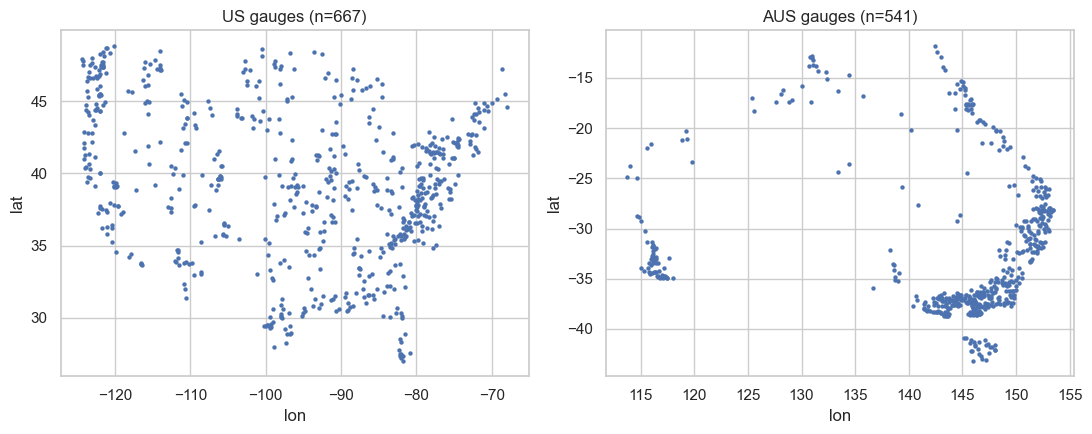

In [11]:
# Gauge locations
# Name the coordinate columns used to map the gauging stations.
lat, lon = "gauge_lat", "gauge_lon"
# Draw maps only when both coordinate fields are present.
if {lat, lon} <= set(attrs.columns):
    # Create one map panel per subset, keeping the axes two-dimensional.
    fig, axes = plt.subplots(1, len(SUBSETS), figsize=(5.5 * len(SUBSETS), 4.5), squeeze=False)
    # Plot each region's basin coordinates in its corresponding panel.
    for ax, s in zip(axes.ravel(), SUBSETS):
        # Select basin locations for the current subset.
        d = attrs[attrs["subset"] == s]
        # Mark each gauge using longitude and latitude.
        sns.scatterplot(data=d, x=lon, y=lat, s=10, linewidth=0, ax=ax)
        # Add the region name, basin count, and coordinate-axis labels.
        ax.set(title=f"{REGION[s]} gauges (n={len(d)})", xlabel="lon", ylabel="lat")
    # Space and render the gauge-location panels.
    plt.tight_layout(); plt.show()

C:\Users\Spencer Childress\AppData\Local\Temp\ipykernel_46256\1473243291.py:23: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(x=x, hue=attrs["subset"].map(REGION), common_norm=False, fill=True, alpha=.3, legend=ax is axes.ravel()[0], ax=ax)


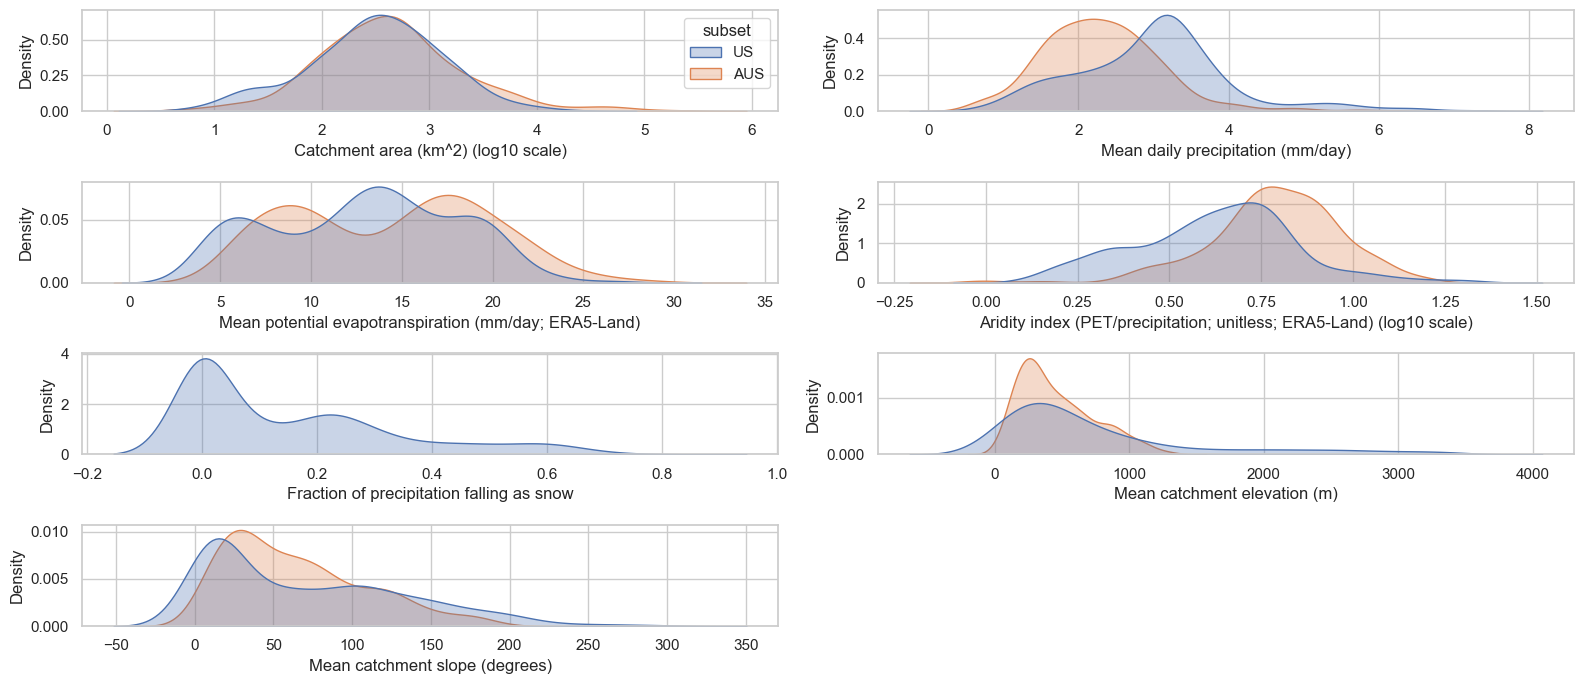

subset,camels,camelsaus
area,340.010004,393.539108
p_mean,3.076459,2.240016
pet_mean_ERA5_LAND,13.332737,15.195936
aridity_ERA5_LAND,4.390515,6.212369
frac_snow,0.071664,0.000000
ele_mt_sav,479.107272,390.898303
slp_dg_sav,56.055614,56.506129


In [12]:
# Key catchment descriptors by region (log scale where heavy-tailed)
# Select key catchment descriptors available in the prepared attributes.
cols = [c for c in ["area", "p_mean", "pet_mean_ERA5_LAND", "aridity_ERA5_LAND", "frac_snow", "ele_mt_sav", "slp_dg_sav"] if c in attrs.columns]
# Give each attribute an interpretable plot label, including units where applicable.
labels = {
    "area": "Catchment area (km^2)",
    "p_mean": "Mean daily precipitation (mm/day)",
    "pet_mean_ERA5_LAND": "Mean potential evapotranspiration (mm/day; ERA5-Land)",
    "aridity_ERA5_LAND": "Aridity index (PET/precipitation; unitless; ERA5-Land)",
    "frac_snow": "Fraction of precipitation falling as snow",
    "ele_mt_sav": "Mean catchment elevation (m)",
    "slp_dg_sav": "Mean catchment slope (degrees)",
}
# Create a grid for comparing each descriptor between regions.
fig, axes = plt.subplots(4, (len(cols) + 1) // 3, figsize=(16, 7))
# Draw one distribution plot for each selected attribute.
for ax, c in zip(axes.ravel(), cols):
    # Use a log transform for selected positive, strongly skewed attributes.
    log = c in ("area", "aridity_ERA5_LAND") and (attrs[c].dropna() > 0).all()
    # Transform the values when requested; otherwise retain their original scale.
    x = np.log10(attrs[c]) if log else attrs[c]
    # Compare region distributions without normalizing their sample sizes together.
    sns.kdeplot(x=x, hue=attrs["subset"].map(REGION), common_norm=False, fill=True, alpha=.3, legend=ax is axes.ravel()[0], ax=ax)
    # Label the horizontal axis with the scale used for this attribute.
    ax.set_xlabel(f"{labels[c]} (log10 scale)" if log else labels[c])
# Hide any unused panels in the grid.
for ax in axes.ravel()[len(cols):]:
    # Remove ticks and borders from an empty panel.
    ax.axis("off")
# Adjust the grid spacing and render the distributions.
plt.tight_layout(); plt.show()
# Compare median descriptor values by subset in a transposed table.
attrs.groupby("subset")[cols].median().T

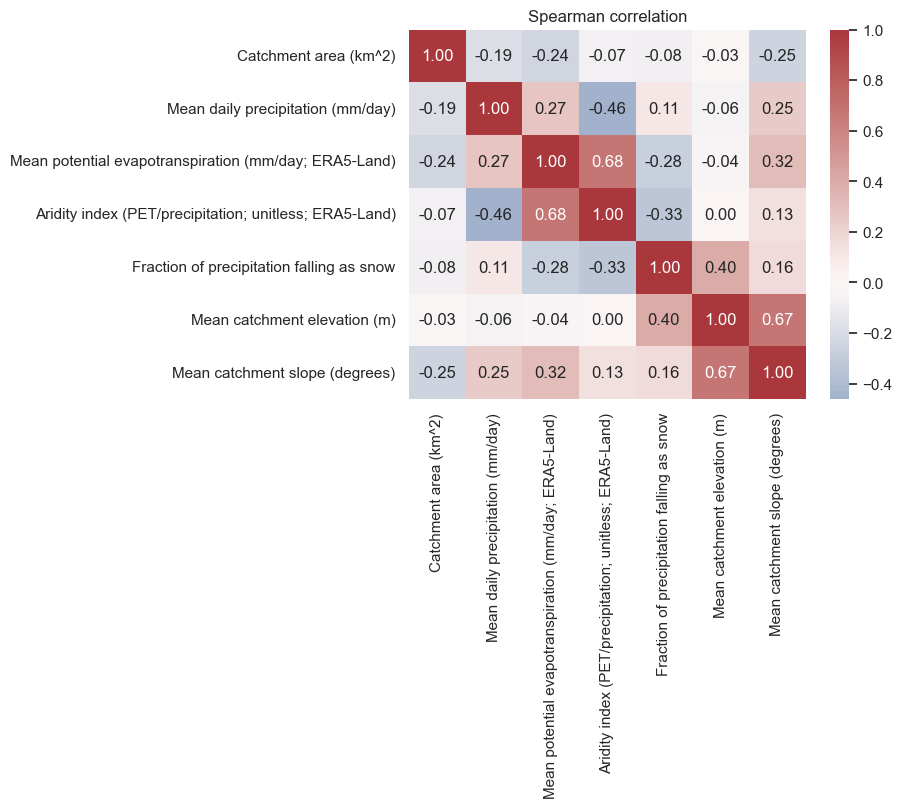

In [13]:
# Climate / physiography correlations among the key attributes
# Keep selected numeric attributes for the correlation calculation.
num = attrs[cols].select_dtypes("number")
# Visualize pairwise rank correlations with annotated coefficients and colors centered at zero.
# Replace raw attribute names on both heatmap axes with the plot descriptions.
corr = num.corr(method="spearman").rename(index=labels, columns=labels)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
# Title and render the correlation heatmap.
plt.title("Spearman correlation"); plt.show()

## 3. Time series

In [14]:
# Define a helper to load one basin's daily series from its subset file.
def load_ts(gauge_id):
    """One basin's daily series from its region's combined parquet."""
    # Use the gauge identifier prefix to choose the correct subset parquet file.
    subset = gauge_id.split("_")[0]
    # Read only rows belonging to the requested basin.
    d = pd.read_parquet(COMBINED / f"{subset}.parquet", filters=[("gauge_id", "==", gauge_id)])
    # Remove the redundant identifier and index the returned rows by date.
    return d.drop(columns="gauge_id").set_index("date")

# Look at one basin first
# Choose the first retained gauge as a concrete example for time-series exploration.
example = attrs.index[0]
# Load all available daily variables for the example basin.
ts = load_ts(example)
# Report the basin identifier, date coverage, and time-series dimensions.
print(example, ts.index.min().date(), "->", ts.index.max().date(), ts.shape)
# Preview the first daily records.
display(ts.head())
# List the streamflow and forcing variables available for this basin.
print("columns:", list(ts.columns))

camels_01013500 1981-01-01 -> 2014-12-31 (12418, 17)


,streamflow,total_precipitation_sum,temperature_2m_min,temperature_2m_mean,temperature_2m_max,potential_evaporation_sum_ERA5_LAND,snow_depth_water_equivalent_mean,dewpoint_temperature_2m_mean,surface_net_solar_radiation_mean,surface_net_thermal_radiation_mean,surface_pressure_mean,u_component_of_wind_10m_mean,v_component_of_wind_10m_mean,volumetric_soil_water_layer_1_mean,volumetric_soil_water_layer_2_mean,volumetric_soil_water_layer_3_mean,volumetric_soil_water_layer_4_mean
date,,,,,,,,,,,,,,,,,
1981-01-01,0.60,0.00,-22.330000,-18.090000,-13.420000,1.02,102.430000,-21.850000,47.009998,-63.910000,98.180000,0.47,-0.29,0.26,0.27,0.29,0.31
1981-01-02,0.58,6.36,-19.900000,-15.520000,-12.270000,0.65,104.000000,-18.360001,23.190001,-8.660000,97.239998,-0.66,0.37,0.26,0.27,0.29,0.31
1981-01-03,0.57,1.24,-31.270000,-25.150000,-13.170000,2.09,109.769997,-30.290001,46.889999,-61.820000,96.900002,4.12,0.58,0.26,0.27,0.29,0.31
1981-01-04,0.56,0.56,-33.720001,-31.580000,-29.639999,0.64,109.809998,-36.639999,50.189999,-55.389999,97.260002,2.66,0.72,0.26,0.26,0.29,0.31
1981-01-05,0.55,0.21,-29.190001,-20.559999,-14.700000,0.98,110.449997,-24.350000,46.759998,-52.099998,97.440002,2.77,-0.31,0.26,0.26,0.29,0.31


columns: ['streamflow', 'total_precipitation_sum', 'temperature_2m_min', 'temperature_2m_mean', 'temperature_2m_max', 'potential_evaporation_sum_ERA5_LAND', 'snow_depth_water_equivalent_mean', 'dewpoint_temperature_2m_mean', 'surface_net_solar_radiation_mean', 'surface_net_thermal_radiation_mean', 'surface_pressure_mean', 'u_component_of_wind_10m_mean', 'v_component_of_wind_10m_mean', 'volumetric_soil_water_layer_1_mean', 'volumetric_soil_water_layer_2_mean', 'volumetric_soil_water_layer_3_mean', 'volumetric_soil_water_layer_4_mean']


In [15]:
# Per-basin record summary for all kept basins (flow stats from section 1, record info from the quality report)
# Join flow statistics with each basin's quality-report details.
rec = pd.concat(flow_stats.values()).join(qr[["subset", "region", "first_valid", "last_valid", "valid_years", "missing_frac"]])
# Compare record length, missingness, and flow statistics by region.
rec.groupby("region")[["valid_years", "missing_frac", "q_zero", "q_mean", "q_max"]].describe().T

region                     AUS          US
valid_years  count  541.000000  667.000000
             mean    27.635613   27.783903
             std      0.744612    0.649523
             min     23.983573   24.000000
             25%     27.704312   28.000000
             50%     27.975359   28.000000
             75%     28.000000   28.000000
             max     28.000000   28.000000
missing_frac count  541.000000  667.000000
             mean     0.013014    0.007718
             std      0.026593    0.023197
             min      0.000000    0.000000
             25%      0.000000    0.000000
             50%      0.000880    0.000000
             75%      0.010560    0.000000
             max      0.143444    0.142857
q_zero       count  541.000000  667.000000
             mean     0.233024    0.069838
             std      0.258093    0.165227
             min      0.000000    0.000000
             25%      0.006442    0.000000
             50%      0.126832    0.000000
             75%      0.407876    0.027057
             max      0.946690    0.975842
q_mean       count  541.000000  667.000000
             mean     0.646549    1.493834
             std      0.873270    1.553541
             min      0.004940    0.007532
             25%      0.150702    0.645257
             50%      0.365754    1.106178
             75%      0.751935    1.746857
             max      6.297346    9.815849
q_max        count  541.000000  667.000000
             mean    75.501053   67.098648
             std     88.956558   53.032219
             min      0.950000    1.450000
             25%     21.389999   26.969999
             50%     41.660000   56.570000
             75%     98.199997   90.544998
             max    679.179993  459.970001

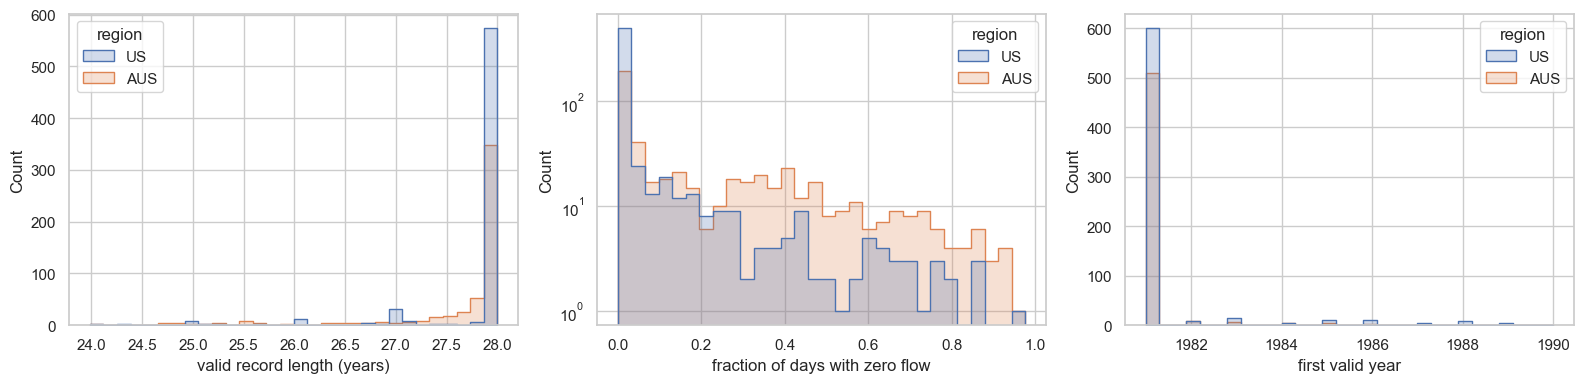

In [16]:
# Create panels for record length, zero-flow fraction, and first valid year.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
# Compare basin record lengths by region and label the horizontal axis.
sns.histplot(data=rec, x="valid_years", hue="region", bins=30, element="step", ax=axes[0]); axes[0].set_xlabel("valid record length (years)")
# Compare zero-flow fractions; a log count scale reveals small bin counts.
sns.histplot(data=rec, x="q_zero", hue="region", bins=30, element="step", ax=axes[1]); axes[1].set_xlabel("fraction of days with zero flow"); axes[1].set_yscale("log")
# Compare when valid streamflow records begin across the basins.
sns.histplot(data=rec, x=rec["first_valid"].dt.year, hue="region", bins=30, element="step", ax=axes[2]); axes[2].set_xlabel("first valid year")
# Adjust spacing and render the three basin-level distributions.
plt.tight_layout(); plt.show()

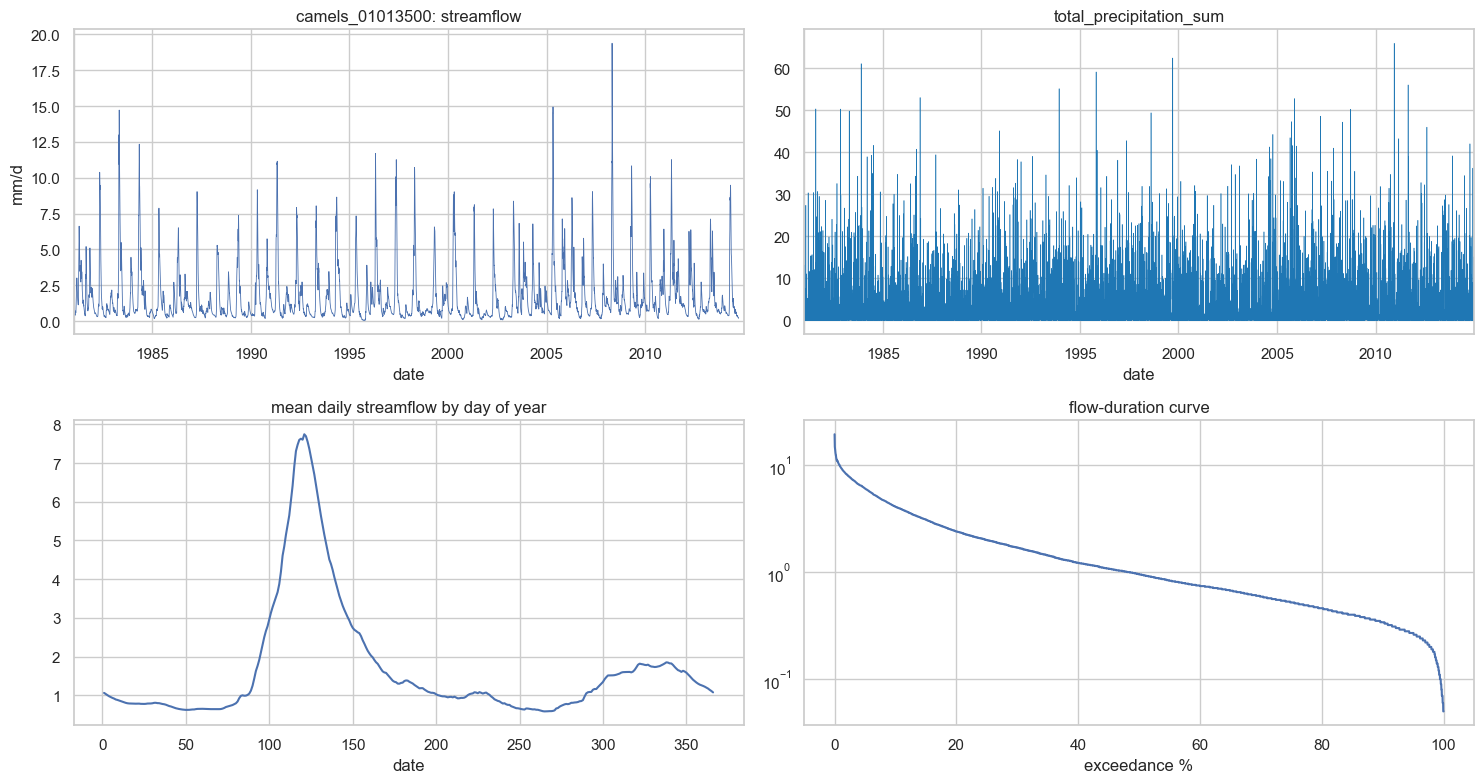

In [17]:
# Streamflow + precipitation for the example basin, plus seasonal cycle and flow-duration curve
# Find the precipitation forcing column, allowing for dataset-specific suffixes.
precip = next((c for c in ts.columns if c.startswith("total_precipitation_sum")), None)
# Find the mean-temperature column so it can be included if available.
temp = next((c for c in ts.columns if c.startswith("temperature_2m_mean")), None)

# Create panels for daily flow, precipitation, seasonal means, and flow duration.
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
# Plot daily streamflow for the example basin and label its units.
ts["streamflow"].plot(ax=axes[0, 0], lw=.6); axes[0, 0].set(title=f"{example}: streamflow", ylabel="mm/d")
# Plot precipitation in the second panel when a matching column exists.
if precip: ts[precip].plot(ax=axes[0, 1], lw=.4, color="tab:blue"); axes[0, 1].set(title=precip)
# Average available flow and forcing variables by day of year for their seasonal cycle.
clim = ts.groupby(ts.index.dayofyear)[["streamflow"] + [c for c in (precip, temp) if c]].mean()
# Plot the seasonal mean streamflow profile.
clim["streamflow"].plot(ax=axes[1, 0]); axes[1, 0].set(title="mean daily streamflow by day of year")
# Sort observed flows from largest to smallest for the flow-duration curve.
q = np.sort(ts["streamflow"].dropna().values)[::-1]
# Plot exceedance percentage against flow on a log scale, clipping zero values for display.
axes[1, 1].semilogy(100 * np.arange(1, len(q) + 1) / len(q), np.clip(q, 1e-4, None))
# Label the flow-duration axes.
axes[1, 1].set(title="flow-duration curve", xlabel="exceedance %")
# Space the four panels and render the example-basin figure.
plt.tight_layout(); plt.show()

In [18]:
# Forcing/target variables: availability and a quick lagged-correlation check with streamflow
# List the ten variables with the greatest fraction of missing observations in this basin.
print(ts.isna().mean().sort_values(ascending=False).head(10).to_string(), "\n")
# Check lagged precipitation-flow correlations when precipitation is available.
if precip:
    # Consider same-day precipitation and delays of up to seven days.
    lags = range(0, 8)
    # Print the correlation at each lag, rounded for concise comparison.
    print({k: round(ts["streamflow"].corr(ts[precip].shift(k)), 3) for k in lags})

streamflow                             0.007409
total_precipitation_sum                0.000000
temperature_2m_min                     0.000000
temperature_2m_mean                    0.000000
temperature_2m_max                     0.000000
potential_evaporation_sum_ERA5_LAND    0.000000
snow_depth_water_equivalent_mean       0.000000
dewpoint_temperature_2m_mean           0.000000
surface_net_solar_radiation_mean       0.000000
surface_net_thermal_radiation_mean     0.000000 

{0: np.float64(0.029), 1: np.float64(0.064), 2: np.float64(0.076), 3: np.float64(0.081), 4: np.float64(0.082), 5: np.float64(0.081), 6: np.float64(0.08), 7: np.float64(0.078)}


## 4. Notes / open questions for review
- Which regions and how many basins do we want for the unmonitored-basin (PUB) experiment? Are the 15-year / 15%-missing filters right, given how many basins they remove?
- Zero-flow days are common in some basins (see `q_zero`): decide the log-transform offset for the target.
- The 1981-2014 window is a guess at a window the two regions share; the completeness-over-time plot shows US coverage falling in 2013-2014, so decide whether to end the window earlier.